### Q12: During which trial segment is variable C best decoded?

Variable C is recorded as 0, 1, or 2. Only 29 retained trials have C=1, distributed across five mice, so C=1 cannot support consistent five-fold within-mouse decoding. The primary analysis therefore decodes **C=0 versus C=2** in every mouse. C=1 remains in the filtered trial table but is explicitly excluded from the decoder.

Three trial segments are compared:

1. `trial_start` to `stim_start`
2. `stim_start` to `outcome`
3. `outcome` to `trial_end`

For every segment and neuron, the feature is mean firing rate in the half-open segment interval. Decoding is performed separately within each mouse and brain area using standardized L2-regularized logistic regression and stratified five-fold cross-validation. The same trial folds, matched neuron counts, and selected neuron subsamples are used across all three segments, making their AUC values directly paired.

Repeated neuron subsamples are averaged within mouse, area, and segment. The primary comparison then averages the three areas within each mouse, so the 18 mice are the observational units. Formal repeated-measures inference and Tukey-adjusted pairwise segment comparisons are performed by `q12_segment_stats.R`, using mouse as a random intercept.

In [1]:
import csv
import os
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

#### Parameters

In [2]:
project_folder = Path(os.environ.get(
    "CON2PHYS_PROJECT_DIR", "E:/con2phys_submission"
))
repository_folder = Path(os.environ.get(
    "CON2PHYS_REPOSITORY_DIR", "D:/git_repos/con2phys_submission"
))
sua_csv_path = Path(os.environ.get(
    "CON2PHYS_SUA_CSV",
    project_folder / "dataset" / "full_sua_dataset.csv",
))
trials_csv_path = repository_folder / "results" / "q12" / "trials_info_filtered.csv"
q_path = Path(os.environ.get(
    "Q12_OUTPUT_DIR", repository_folder / "results" / "q12"
))

N_NEURON_SUBSAMPLES = int(os.environ.get("Q12_N_SUBSAMPLES", 20))
N_CV_SPLITS = 5
RANDOM_SEED = 42
EXPECTED_N_MICE = 18
EXPECTED_N_UNITS = 1_449
EXPECTED_BRAIN_AREAS = (1, 2, 3)
DECODED_C_LEVELS = (0, 2)
SEGMENTS = (
    ("trial_start_to_stim", "trial_start", "stim_start", "Trial start to stimulus"),
    ("stim_to_outcome", "stim_start", "outcome", "Stimulus to outcome"),
    ("outcome_to_trial_end", "outcome", "trial_end", "Outcome to trial end"),
)
SEGMENT_NAMES = tuple(segment[0] for segment in SEGMENTS)
SEGMENT_LABELS = {segment[0]: segment[3] for segment in SEGMENTS}

MAX_MICE = (
    int(os.environ["Q12_MAX_MICE"])
    if os.environ.get("Q12_MAX_MICE")
    else None
)
run_tag = "full" if MAX_MICE is None else f"first_{MAX_MICE}_mice"
file_suffix = "" if MAX_MICE is None else f"_{run_tag}"

unit_counts_csv_path = q_path / f"q12_unit_counts{file_suffix}.csv"
subsamples_csv_path = q_path / f"q12_auc_subsamples{file_suffix}.csv"
mouse_area_segment_csv_path = q_path / f"q12_auc_mouse_area_segment{file_suffix}.csv"
mouse_segment_csv_path = q_path / f"q12_auc_mouse_segment{file_suffix}.csv"
segment_summary_csv_path = q_path / f"q12_auc_segment_summary{file_suffix}.csv"
primary_figure_path = q_path / f"q12_auc_by_segment{file_suffix}.png"
area_figure_path = q_path / f"q12_auc_by_segment_and_area{file_suffix}.png"

RUN_CONFIG = {
    "target": "variable_C_0_vs_2",
    "excluded_target_level": "C=1_due_to_29_trials_across_5_mice",
    "features": "mean_firing_rate_in_each_trial_segment",
    "interval_convention": "segment_start_inclusive_segment_end_exclusive",
    "decoder": "standardized_l2_logistic_regression",
    "metric": "cross_validated_roc_auc_for_C2",
    "cv": f"{N_CV_SPLITS}_fold_stratified_within_mouse",
    "neuron_matching": "minimum_area_population_within_mouse",
    "paired_design": "same_cv_folds_and_neuron_subsamples_across_segments",
    "n_neuron_subsamples": N_NEURON_SUBSAMPLES,
    "random_seed": RANDOM_SEED,
    "max_mice": MAX_MICE,
}
RUN_CONFIG

{'target': 'variable_C_0_vs_2',
 'excluded_target_level': 'C=1_due_to_29_trials_across_5_mice',
 'features': 'mean_firing_rate_in_each_trial_segment',
 'interval_convention': 'segment_start_inclusive_segment_end_exclusive',
 'decoder': 'standardized_l2_logistic_regression',
 'metric': 'cross_validated_roc_auc_for_C2',
 'cv': '5_fold_stratified_within_mouse',
 'neuron_matching': 'minimum_area_population_within_mouse',
 'paired_design': 'same_cv_folds_and_neuron_subsamples_across_segments',
 'n_neuron_subsamples': 20,
 'random_seed': 42,
 'max_mice': None}

#### Load and validate filtered trials

The Q12 filtered table uses the Q11 selection criteria. All retained trials remain in this table. Only C=0 and C=2 trials enter the binary decoder.

In [3]:
required_paths = [sua_csv_path, trials_csv_path]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f"Required paths not found: {missing_paths}")

all_trials_df = pd.read_csv(trials_csv_path)
expected_trial_columns = [
    "mouse_id", "trial_id", "variable_A", "variable_B", "variable_C",
    "trial_start", "stim_start", "outcome", "trial_end", "trial_duration",
]
if list(all_trials_df.columns) != expected_trial_columns:
    raise ValueError(f"Unexpected trial schema: {list(all_trials_df.columns)}")
if all_trials_df[expected_trial_columns].isna().any().any():
    raise ValueError("Filtered trial table contains missing values")
if all_trials_df[["mouse_id", "trial_id"]].duplicated().any():
    raise ValueError("Duplicate mouse/trial identifiers found")

correct_order = (
    all_trials_df["trial_start"].lt(all_trials_df["stim_start"])
    & all_trials_df["stim_start"].lt(all_trials_df["outcome"])
    & all_trials_df["outcome"].lt(all_trials_df["trial_end"])
)
if not correct_order.all():
    raise ValueError("Filtered trial table contains incorrectly ordered events")
calculated_duration = all_trials_df["trial_end"] - all_trials_df["trial_start"]
if not np.allclose(
    all_trials_df["trial_duration"], calculated_duration, rtol=0, atol=1e-9
):
    raise ValueError("trial_duration does not match trial_end - trial_start")
if set(all_trials_df["variable_C"].unique()) != {0, 1, 2}:
    raise ValueError(
        f"Expected variable_C values 0, 1, 2; "
        f"found {sorted(all_trials_df['variable_C'].unique())}"
    )

all_mouse_ids = sorted(int(mouse_id) for mouse_id in all_trials_df["mouse_id"].unique())
if len(all_mouse_ids) != EXPECTED_N_MICE:
    raise ValueError(
        f"Expected {EXPECTED_N_MICE} mice, found {len(all_mouse_ids)}"
    )
selected_mouse_ids = (
    all_mouse_ids if MAX_MICE is None else all_mouse_ids[:MAX_MICE]
)

selected_trials_df = (
    all_trials_df.loc[all_trials_df["mouse_id"].isin(selected_mouse_ids)]
    .sort_values(["mouse_id", "trial_id"])
    .reset_index(drop=True)
)
all_class_counts = (
    pd.crosstab(selected_trials_df["mouse_id"], selected_trials_df["variable_C"])
    .reindex(index=selected_mouse_ids, columns=(0, 1, 2), fill_value=0)
)
decode_trials_df = (
    selected_trials_df.loc[
        selected_trials_df["variable_C"].isin(DECODED_C_LEVELS)
    ]
    .reset_index(drop=True)
)
decode_class_counts = (
    pd.crosstab(decode_trials_df["mouse_id"], decode_trials_df["variable_C"])
    .reindex(index=selected_mouse_ids, columns=DECODED_C_LEVELS, fill_value=0)
)
if (decode_class_counts.min(axis=1) < N_CV_SPLITS).any():
    raise ValueError("A mouse has too few C=0 or C=2 trials for five-fold CV")

trials_by_mouse = {
    int(mouse_id): group.reset_index(drop=True)
    for mouse_id, group in decode_trials_df.groupby("mouse_id", sort=True)
}
print(
    f"Validated {len(selected_trials_df):,} retained trials from "
    f"{len(selected_mouse_ids)} mice."
)
print(
    f"Decoder uses {len(decode_trials_df):,} C=0/C=2 trials and excludes "
    f"{int((selected_trials_df['variable_C'] == 1).sum())} C=1 trials."
)
display(all_class_counts.rename(columns={0: "C=0", 1: "C=1", 2: "C=2"}))

Validated 10,350 retained trials from 18 mice.
Decoder uses 10,321 C=0/C=2 trials and excludes 29 C=1 trials.


variable_C,C=0,C=1,C=2
mouse_id,,,
1,205,0,202
2,390,0,459
3,168,0,305
4,235,0,269
5,216,0,207
6,206,0,264
7,221,7,247
8,376,0,286
9,313,13,253


#### Extract segment-specific firing rates

The approximately 802 MB SUA table is streamed once. For each neuron, spike counts are obtained by binary searches in the three half-open segment intervals and divided by the physical segment durations. This produces one trial-by-neuron matrix for every mouse, area, and segment.

In [4]:
expected_sua_columns = [
    "mouse_id", "cluster_id", "brain_area", "recording_duration_sec",
    "unit_last_spike_sec", "n_spikes", "spikes",
]

segment_windows_by_mouse = {}
for mouse_id, mouse_trials in trials_by_mouse.items():
    for segment_name, start_column, end_column, _ in SEGMENTS:
        starts = mouse_trials[start_column].to_numpy(dtype=float)
        ends = mouse_trials[end_column].to_numpy(dtype=float)
        durations = ends - starts
        if not np.isfinite(durations).all() or np.any(durations <= 0):
            raise ValueError(
                f"Invalid {segment_name} duration for mouse {mouse_id}"
            )
        segment_windows_by_mouse[(mouse_id, segment_name)] = (
            starts, ends, durations
        )

rate_columns_by_segment_group = {
    segment_name: defaultdict(list) for segment_name in SEGMENT_NAMES
}
cluster_ids_by_group = defaultdict(list)
unit_keys = set()
n_source_units = 0

csv.field_size_limit(2**31 - 1)
load_started = time.perf_counter()
with sua_csv_path.open(newline="", encoding="utf-8") as handle:
    reader = csv.DictReader(handle)
    if reader.fieldnames != expected_sua_columns:
        raise ValueError(f"Unexpected SUA schema: {reader.fieldnames}")

    for row in reader:
        n_source_units += 1
        mouse_id = int(row["mouse_id"])
        if mouse_id not in trials_by_mouse:
            continue

        cluster_id = int(row["cluster_id"])
        brain_area = int(row["brain_area"])
        unit_key = (mouse_id, cluster_id)
        group_key = (mouse_id, brain_area)
        if unit_key in unit_keys:
            raise ValueError(f"Duplicate unit key: {unit_key}")
        if brain_area not in EXPECTED_BRAIN_AREAS:
            raise ValueError(f"Unexpected brain area for {unit_key}: {brain_area}")

        spike_times = np.fromstring(row["spikes"], sep=";", dtype=np.float64)
        expected_n_spikes = int(row["n_spikes"])
        if spike_times.size != expected_n_spikes or spike_times.size == 0:
            raise ValueError(f"Spike-count mismatch for {unit_key}")
        if not np.isfinite(spike_times).all() or np.any(np.diff(spike_times) < 0):
            raise ValueError(f"Invalid or unsorted spikes for {unit_key}")

        for segment_name in SEGMENT_NAMES:
            starts, ends, durations = segment_windows_by_mouse[
                (mouse_id, segment_name)
            ]
            left = np.searchsorted(spike_times, starts, side="left")
            right = np.searchsorted(spike_times, ends, side="left")
            firing_rates = (right - left) / durations
            rate_columns_by_segment_group[segment_name][group_key].append(
                firing_rates
            )

        cluster_ids_by_group[group_key].append(cluster_id)
        unit_keys.add(unit_key)

if MAX_MICE is None and n_source_units != EXPECTED_N_UNITS:
    raise ValueError(
        f"Expected {EXPECTED_N_UNITS} SUA units, found {n_source_units}"
    )

expected_group_keys = {
    (int(mouse_id), int(area))
    for mouse_id in selected_mouse_ids
    for area in EXPECTED_BRAIN_AREAS
}
for segment_name in SEGMENT_NAMES:
    observed_keys = set(rate_columns_by_segment_group[segment_name])
    if observed_keys != expected_group_keys:
        raise ValueError(
            f"Missing {segment_name} groups: "
            f"{sorted(expected_group_keys - observed_keys)}"
        )

firing_rates_by_segment_group = {segment: {} for segment in SEGMENT_NAMES}
unit_count_rows = []
for group_key in sorted(expected_group_keys):
    mouse_id, brain_area = group_key
    n_units = len(cluster_ids_by_group[group_key])
    expected_rows = len(trials_by_mouse[mouse_id])
    for segment_name in SEGMENT_NAMES:
        matrix = np.column_stack(
            rate_columns_by_segment_group[segment_name][group_key]
        )
        if matrix.shape != (expected_rows, n_units):
            raise ValueError(
                f"Unexpected matrix shape for {segment_name}, {group_key}: "
                f"{matrix.shape}"
            )
        if not np.isfinite(matrix).all():
            raise ValueError(
                f"Non-finite firing rates for {segment_name}, {group_key}"
            )
        firing_rates_by_segment_group[segment_name][group_key] = matrix

    unit_count_rows.append({
        "mouse_id": mouse_id,
        "brain_area": brain_area,
        "n_units": n_units,
        "n_decoding_trials": expected_rows,
    })

unit_counts_df = pd.DataFrame(unit_count_rows)
matched_units_by_mouse = (
    unit_counts_df.groupby("mouse_id")["n_units"].min().astype(int)
)
unit_counts_df["n_matched_units"] = unit_counts_df["mouse_id"].map(
    matched_units_by_mouse
)
q_path.mkdir(parents=True, exist_ok=True)
unit_counts_df.to_csv(unit_counts_csv_path, index=False)

print(
    f"Built {len(SEGMENT_NAMES) * len(expected_group_keys)} segment matrices "
    f"in {time.perf_counter() - load_started:.1f} s."
)
display(unit_counts_df)

Built 162 segment matrices in 20.7 s.


,mouse_id,brain_area,n_units,n_decoding_trials,n_matched_units
0,1,1,59,407,7
1,1,2,22,407,7
2,1,3,7,407,7
3,2,1,40,849,19
4,2,2,20,849,19
5,2,3,19,849,19
6,3,1,47,473,12
7,3,2,26,473,12
8,3,3,12,473,12
9,4,1,34,504,6


#### Paired matched-population decoding

Within a mouse, the same trial folds are used for every area and segment. Within each mouse, area, and neuron-subsample repetition, one set of units is selected and reused for all three segments.

In [5]:
def make_decoder():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            solver="liblinear",
            class_weight="balanced",
            max_iter=1_000,
            random_state=RANDOM_SEED,
        ),
    )


rng = np.random.default_rng(RANDOM_SEED)
result_rows = []
decoding_started = time.perf_counter()

for mouse_number, mouse_id in enumerate(selected_mouse_ids, start=1):
    mouse_started = time.perf_counter()
    mouse_trials = trials_by_mouse[int(mouse_id)]
    raw_labels = mouse_trials["variable_C"].to_numpy(dtype=int)
    y = (raw_labels == 2).astype(int)
    cv = StratifiedKFold(
        n_splits=N_CV_SPLITS,
        shuffle=True,
        random_state=RANDOM_SEED + int(mouse_id),
    )
    cv_splits = list(cv.split(np.zeros(y.size), y))
    n_matched_units = int(matched_units_by_mouse.loc[mouse_id])

    for subsample_id in range(1, N_NEURON_SUBSAMPLES + 1):
        for brain_area in EXPECTED_BRAIN_AREAS:
            group_key = (int(mouse_id), int(brain_area))
            n_available_units = len(cluster_ids_by_group[group_key])
            selected_indices = np.sort(rng.choice(
                n_available_units, size=n_matched_units, replace=False
            ))
            selected_cluster_ids = np.asarray(
                cluster_ids_by_group[group_key]
            )[selected_indices]
            cluster_id_text = ";".join(map(str, selected_cluster_ids))

            for segment_name in SEGMENT_NAMES:
                full_matrix = firing_rates_by_segment_group[
                    segment_name
                ][group_key]
                x = full_matrix[:, selected_indices]
                probabilities = cross_val_predict(
                    make_decoder(), x, y,
                    cv=cv_splits,
                    method="predict_proba",
                    n_jobs=1,
                )[:, 1]
                auc = roc_auc_score(y, probabilities)
                result_rows.append({
                    "mouse_id": int(mouse_id),
                    "brain_area": int(brain_area),
                    "segment": segment_name,
                    "segment_label": SEGMENT_LABELS[segment_name],
                    "subsample_id": subsample_id,
                    "n_matched_units": n_matched_units,
                    "n_trials": y.size,
                    "n_C0": int((raw_labels == 0).sum()),
                    "n_C2": int((raw_labels == 2).sum()),
                    "roc_auc": auc,
                    "cluster_ids": cluster_id_text,
                })

    elapsed = time.perf_counter() - mouse_started
    print(
        f"Mouse {mouse_id}: {n_matched_units} matched units, "
        f"{N_NEURON_SUBSAMPLES} subsamples x {len(SEGMENT_NAMES)} segments, "
        f"{elapsed:.1f} s ({mouse_number}/{len(selected_mouse_ids)})"
    )

auc_subsamples_df = pd.DataFrame(result_rows)
expected_result_rows = (
    len(selected_mouse_ids)
    * len(EXPECTED_BRAIN_AREAS)
    * N_NEURON_SUBSAMPLES
    * len(SEGMENT_NAMES)
)
if len(auc_subsamples_df) != expected_result_rows:
    raise ValueError(
        f"Expected {expected_result_rows:,} decoder results, "
        f"found {len(auc_subsamples_df):,}"
    )
if not auc_subsamples_df["roc_auc"].between(0, 1).all():
    raise ValueError("ROC-AUC outside [0, 1]")

paired_cluster_check = (
    auc_subsamples_df.groupby(
        ["mouse_id", "brain_area", "subsample_id"]
    )["cluster_ids"].nunique()
)
if not paired_cluster_check.eq(1).all():
    raise ValueError("Neuron subsamples are not identical across segments")

auc_subsamples_df.to_csv(subsamples_csv_path, index=False)
print(
    f"Completed {len(auc_subsamples_df):,} paired segment decoders in "
    f"{time.perf_counter() - decoding_started:.1f} s."
)
auc_subsamples_df.head()

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

... (361 outputs left out)

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\con2phys\lib\python\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
 

Mouse 18: 12 matched units, 20 subsamples x 3 segments, 4.0 s (18/18)
Completed 3,240 paired segment decoders in 74.1 s.


,mouse_id,brain_area,segment,segment_label,subsample_id,n_matched_units,n_trials,n_C0,n_C2,roc_auc,cluster_ids
0,1,1,trial_start_to_stim,Trial start to stimulus,1,7,407,205,202,0.558585,391;392;445;471;488;509;879
1,1,1,stim_to_outcome,Stimulus to outcome,1,7,407,205,202,0.699686,391;392;445;471;488;509;879
2,1,1,outcome_to_trial_end,Outcome to trial end,1,7,407,205,202,0.623400,391;392;445;471;488;509;879
3,1,2,trial_start_to_stim,Trial start to stimulus,1,7,407,205,202,0.470502,709;732;758;762;787;790;937
4,1,2,stim_to_outcome,Stimulus to outcome,1,7,407,205,202,0.651630,709;732;758;762;787;790;937


#### Mouse-level segment summaries

Neuron subsamples are first averaged within mouse, area, and segment. The primary segment estimate then averages the three brain areas within each mouse, so the 18 mice are the observational units. Formal repeated-measures inference, Tukey-adjusted pairwise comparisons, and the two standard statistical plots are generated by `q12_segment_stats.R` from `q12_auc_mouse_segment.csv`.

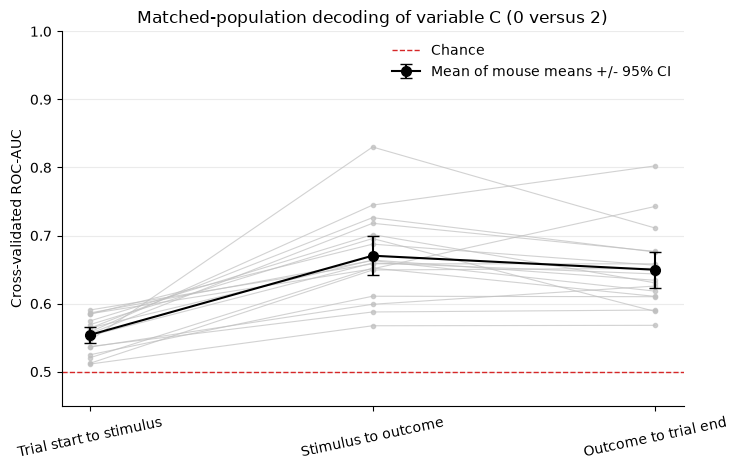

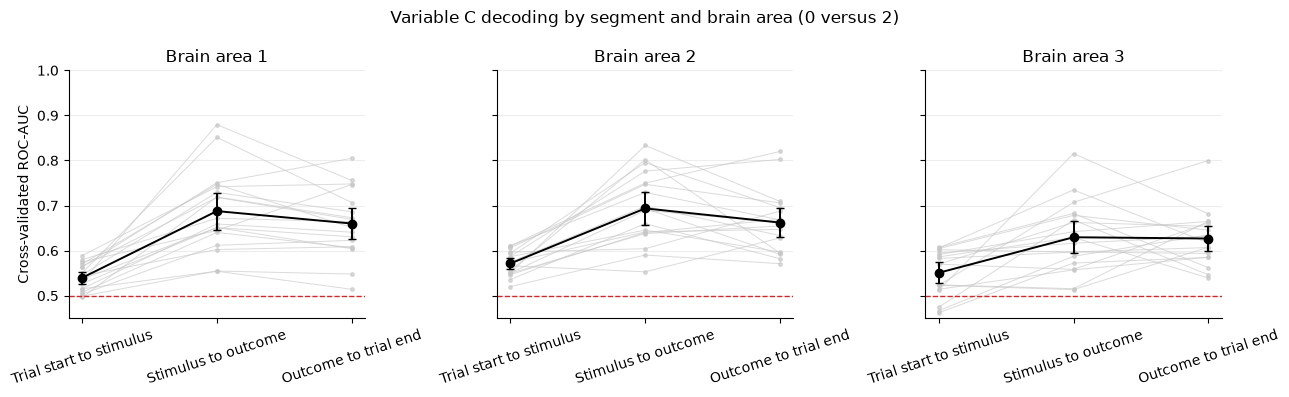

,segment,segment_label,mean_roc_auc,sd_mouse_auc,n_mice,sem_roc_auc,ci95_margin,ci95_low,ci95_high
0,trial_start_to_stim,Trial start to stimulus,0.554012,0.025877,18,0.006099,0.011954,0.542057,0.565966
1,stim_to_outcome,Stimulus to outcome,0.670359,0.062248,18,0.014672,0.028757,0.641602,0.699116
2,outcome_to_trial_end,Outcome to trial end,0.649735,0.057633,18,0.013584,0.026625,0.623110,0.676360


Highest mean ROC-AUC: Stimulus to outcome (0.6704, 95% CI 0.6416-0.6991).


In [6]:
segment_order = {name: index for index, name in enumerate(SEGMENT_NAMES)}

mouse_area_segment_auc = (
    auc_subsamples_df.groupby(
        ["mouse_id", "brain_area", "segment", "segment_label"],
        as_index=False,
        sort=False,
    )
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        sd_subsample_roc_auc=("roc_auc", "std"),
        n_subsamples=("roc_auc", "size"),
        n_matched_units=("n_matched_units", "first"),
        n_trials=("n_trials", "first"),
        n_C0=("n_C0", "first"),
        n_C2=("n_C2", "first"),
    )
)
if not mouse_area_segment_auc["n_subsamples"].eq(N_NEURON_SUBSAMPLES).all():
    raise ValueError("Unexpected number of neuron subsamples in summary")
mouse_area_segment_auc["segment_order"] = mouse_area_segment_auc["segment"].map(
    segment_order
)
mouse_area_segment_auc = mouse_area_segment_auc.sort_values(
    ["mouse_id", "brain_area", "segment_order"]
).drop(columns="segment_order")

mouse_segment_auc = (
    mouse_area_segment_auc.groupby(
        ["mouse_id", "segment", "segment_label"],
        as_index=False,
        sort=False,
    )
    .agg(
        mean_roc_auc=("mean_roc_auc", "mean"),
        sd_across_areas=("mean_roc_auc", "std"),
        n_areas=("brain_area", "nunique"),
        n_trials=("n_trials", "first"),
        n_C0=("n_C0", "first"),
        n_C2=("n_C2", "first"),
        n_matched_units=("n_matched_units", "first"),
    )
)
if not mouse_segment_auc["n_areas"].eq(len(EXPECTED_BRAIN_AREAS)).all():
    raise ValueError("Mouse-segment summary does not contain all three areas")
mouse_segment_auc["segment_order"] = mouse_segment_auc["segment"].map(
    segment_order
)
mouse_segment_auc = mouse_segment_auc.sort_values(
    ["mouse_id", "segment_order"]
).drop(columns="segment_order")

segment_summary = (
    mouse_segment_auc.groupby(
        ["segment", "segment_label"], as_index=False, sort=False
    )["mean_roc_auc"]
    .agg(mean_roc_auc="mean", sd_mouse_auc="std", n_mice="count")
)
segment_summary["sem_roc_auc"] = (
    segment_summary["sd_mouse_auc"] / np.sqrt(segment_summary["n_mice"])
)
segment_summary["ci95_margin"] = 1.96 * segment_summary["sem_roc_auc"]
segment_summary["ci95_low"] = (
    segment_summary["mean_roc_auc"] - segment_summary["ci95_margin"]
)
segment_summary["ci95_high"] = (
    segment_summary["mean_roc_auc"] + segment_summary["ci95_margin"]
)
segment_summary["segment_order"] = segment_summary["segment"].map(segment_order)
segment_summary = segment_summary.sort_values("segment_order").drop(
    columns="segment_order"
)


mouse_area_segment_auc.to_csv(mouse_area_segment_csv_path, index=False)
mouse_segment_auc.to_csv(mouse_segment_csv_path, index=False)
segment_summary.to_csv(segment_summary_csv_path, index=False)

x_positions = np.arange(len(SEGMENT_NAMES), dtype=float)
x_labels = [SEGMENT_LABELS[name] for name in SEGMENT_NAMES]

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for mouse_id, mouse_df in mouse_segment_auc.groupby("mouse_id"):
    mouse_values = (
        mouse_df.set_index("segment").loc[list(SEGMENT_NAMES), "mean_roc_auc"]
    )
    ax.plot(
        x_positions, mouse_values,
        color="0.75", marker="o", markersize=3, linewidth=0.8, alpha=0.7,
    )
ax.errorbar(
    x_positions,
    segment_summary["mean_roc_auc"],
    yerr=segment_summary["ci95_margin"],
    fmt="o-", color="black", markersize=7, capsize=4, linewidth=1.5,
    label="Mean of mouse means +/- 95% CI",
)
ax.axhline(0.5, color="tab:red", linestyle="--", linewidth=1, label="Chance")
ax.set_xticks(x_positions, x_labels, rotation=12)
ax.set_ylabel("Cross-validated ROC-AUC")
ax.set_title("Matched-population decoding of variable C (0 versus 2)")
ax.set_ylim(0.45, 1.0)
ax.grid(True, axis="y", alpha=0.25)
ax.legend(frameon=False, loc="best")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(primary_figure_path, dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for axis, brain_area in zip(axes, EXPECTED_BRAIN_AREAS):
    area_df = mouse_area_segment_auc.loc[
        mouse_area_segment_auc["brain_area"] == brain_area
    ]
    for mouse_id, mouse_df in area_df.groupby("mouse_id"):
        mouse_values = (
            mouse_df.set_index("segment").loc[
                list(SEGMENT_NAMES), "mean_roc_auc"
            ]
        )
        axis.plot(
            x_positions, mouse_values,
            color="0.78", marker="o", markersize=2.5,
            linewidth=0.7, alpha=0.65,
        )
    area_summary = (
        area_df.groupby("segment")["mean_roc_auc"]
        .agg(["mean", "std", "count"])
        .reindex(SEGMENT_NAMES)
    )
    area_ci = 1.96 * area_summary["std"] / np.sqrt(area_summary["count"])
    axis.errorbar(
        x_positions, area_summary["mean"], yerr=area_ci,
        fmt="o-", color="black", markersize=6, capsize=3, linewidth=1.4,
    )
    axis.axhline(0.5, color="tab:red", linestyle="--", linewidth=1)
    axis.set_title(f"Brain area {brain_area}")
    axis.set_xticks(x_positions, x_labels, rotation=18)
    axis.set_ylim(0.45, 1.0)
    axis.grid(True, axis="y", alpha=0.22)
    sns.despine(ax=axis)
axes[0].set_ylabel("Cross-validated ROC-AUC")
fig.suptitle("Variable C decoding by segment and brain area (0 versus 2)")
fig.tight_layout()
fig.savefig(area_figure_path, dpi=200, bbox_inches="tight")
plt.show()

display(segment_summary)
best_row = segment_summary.loc[segment_summary["mean_roc_auc"].idxmax()]
print(
    f"Highest mean ROC-AUC: {best_row['segment_label']} "
    f"({best_row['mean_roc_auc']:.4f}, "
    f"95% CI {best_row['ci95_low']:.4f}-{best_row['ci95_high']:.4f})."
)